In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 891
Number of columns: 15


In [6]:
print(df.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [7]:
df = df[["survived", "pclass", "sex", "age", "fare"]]

df.head()

,survived,pclass,sex,age,fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64


In [9]:
print("Dataset shape before cleaning:", df.shape)

df = df.dropna()

print("Dataset shape after cleaning:", df.shape)

Dataset shape before cleaning: (891, 5)
Dataset shape after cleaning: (714, 5)


In [10]:
df["sex"] = (df["sex"] == "female").astype(int)

df.head()

,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [11]:
print(df["sex"].value_counts())

sex
0    453
1    261
Name: count, dtype: int64


In [12]:
X = df.drop(columns="survived")
y = df["survived"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   pclass  sex   age     fare
0       3    0  22.0   7.2500
1       1    1  38.0  71.2833
2       3    1  26.0   7.9250
3       1    1  35.0  53.1000
4       3    0  35.0   8.0500

Target:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (571, 4)
Testing data: (143, 4)


In [14]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 571
Testing samples: 143


In [15]:
baseline = max(y_test.mean(), 1 - y_test.mean())

print("Baseline Accuracy:", round(baseline, 3))

Baseline Accuracy: 0.594


In [16]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

In [17]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 1
 0 1 0 0 0 0 1 0 0 1 0 1 1 1 0 1 1 1 1 0 0 0 0 1 1 0 0 0 0 0 1 0 1 1 0 1 0
 0 0 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 1 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0
 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 1 0 1 0 1 1 1 1 0 0 0 1 0 0 1]


In [19]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
0,1,1
1,1,0
2,0,0
3,0,0
4,1,0
5,0,0
6,0,0
7,0,0
8,0,0
9,1,1


In [20]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 3))
print("Model Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.797
Model Accuracy Percentage: 79.72 %


In [21]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[72 13]
 [16 42]]


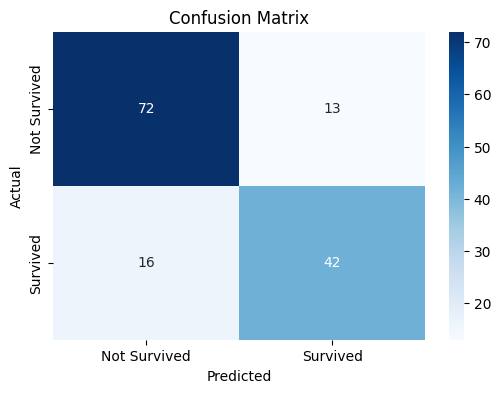

In [22]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [23]:
print("Baseline Accuracy:", round(baseline, 3))
print("Decision Tree Accuracy:", round(accuracy, 3))

if accuracy > baseline:
    print("Decision Tree performed better than baseline!")
else:
    print("Decision Tree did not beat the baseline.")

Baseline Accuracy: 0.594
Decision Tree Accuracy: 0.797
Decision Tree performed better than baseline!


In [24]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

  Feature  Importance
1     sex    0.545075
0  pclass    0.235003
2     age    0.137570
3    fare    0.082352


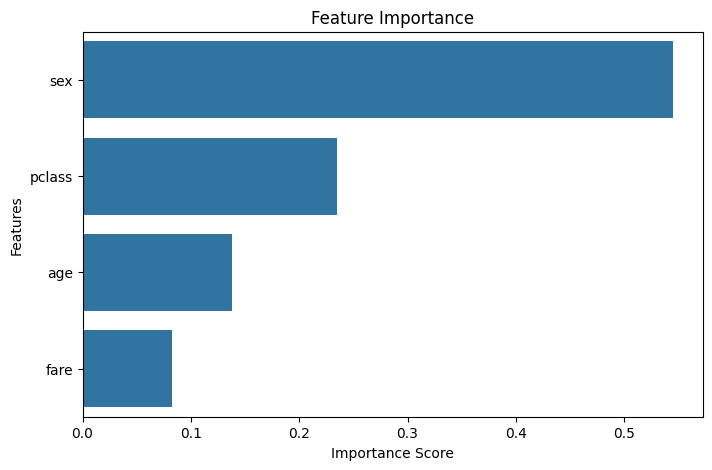

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [26]:
train_accuracies = []
test_accuracies = []
depths = range(1, 13)

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    test_pred = tree.predict(X_test)

    train_accuracies.append(
        accuracy_score(y_train, train_pred)
    )

    test_accuracies.append(
        accuracy_score(y_test, test_pred)
    )

print("Depth testing completed!")

Depth testing completed!


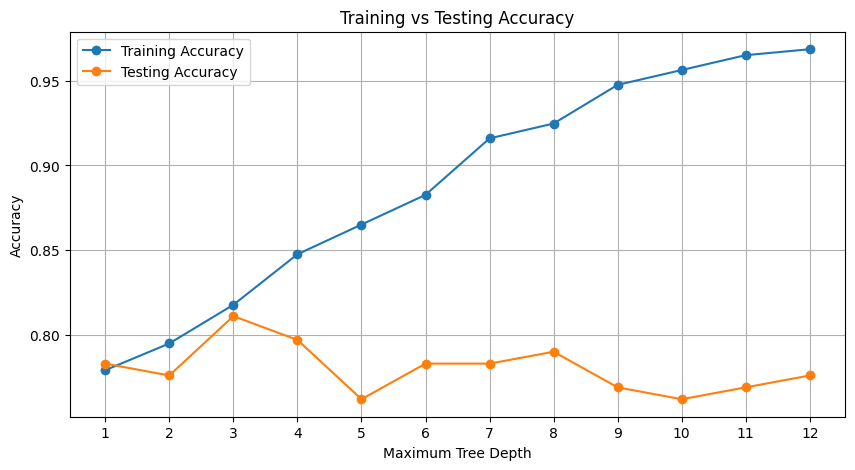

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    depths,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    test_accuracies,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)

plt.show()

In [28]:
print("========== PROJECT 04 RESULTS ==========")

print("Dataset: Titanic")

print("Algorithm: Decision Tree Classifier")

print("Maximum Tree Depth: 4")

print("Baseline Accuracy:",
      round(baseline * 100, 2), "%")

print("Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nFeature Importance:")
print(importance)

print("\nProject Completed Successfully!")

========== PROJECT 04 RESULTS ==========
Dataset: Titanic
Algorithm: Decision Tree Classifier
Maximum Tree Depth: 4
Baseline Accuracy: 59.44 %
Model Accuracy: 79.72 %

Feature Importance:
  Feature  Importance
1     sex    0.545075
0  pclass    0.235003
2     age    0.137570
3    fare    0.082352

Project Completed Successfully!


# Project 04 – First Machine Learning Classifier

## Objective
To build a Decision Tree Classification model using the Titanic dataset to predict passenger survival.

## Technologies Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-Learn

## Methodology
1. Loaded the Titanic dataset.
2. Selected the required columns.
3. Handled missing values.
4. Converted gender into numerical values.
5. Split the dataset into training and testing sets.
6. Calculated baseline accuracy.
7. Trained a Decision Tree Classifier.
8. Evaluated the model using accuracy and a confusion matrix.
9. Tested different tree depths to understand overfitting.

## Conclusion
Successfully developed a Decision Tree Machine Learning classifier to predict Titanic passenger survival. Evaluated its performance against a baseline and studied feature importance and overfitting using different tree depths.

## Limitation
The model uses only four features and a relatively small dataset. Therefore, its predictions may not generalize perfectly to other passenger populations.